# ЛР-4. Случайный лес

Своя реализация (`src/ensemble.py`): бэггинг (бутстрап-подвыборка) + случайное
подпространство признаков в каждом узле. Лес усредняет деревья и снижает дисперсию.

In [1]:
# --- общая подготовка: путь к корню репозитория, импорт своих модулей ---
import sys
from pathlib import Path

# корень репозитория ищем вверх по дереву по маркеру src/ — ноутбук можно
# запускать из своей папки или из корня
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.prep import StandardScaler, time_split
from src import metrics

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (7.5, 4)
plt.rcParams["axes.grid"] = True

In [2]:
# без файлов из data/processed дальше ничего не запустится — подсказываем, как их получить
for _name in ("shares_features.csv", "bonds_features.csv"):
    if not (ROOT / "data" / "processed" / _name).exists():
        raise FileNotFoundError(
            f"нет data/processed/{_name}: сначала выполни "
            "python scripts/fetch_moex.py и python scripts/build_features.py (см. README)"
        )

# --- данные: панели MOEX и хронологическое разбиение ---
shares = pd.read_csv(ROOT / "data/processed/shares_features.csv", parse_dates=["date"])
bonds = pd.read_csv(ROOT / "data/processed/bonds_features.csv", parse_dates=["date"])

SHARE_FEATS = [
    "ret_1", "ret_2", "ret_3", "ret_5", "ret_10", "ret_20",      # лаги доходности
    "vol_5", "vol_20",                                            # волатильность
    "ma_ratio_5", "ma_ratio_20",                                  # отклонение от средних
    "hl_range", "oc_range",                                       # диапазон дня
    "vol_rel", "val_rel", "trd_rel",                              # относительные объёмы
    "rsi_14", "weekday", "month", "market_ret_1",                 # RSI, календарь, рынок
]
BOND_FEATS = [
    "YIELDCLOSE", "dyield_1", "dyield_5", "dyield_20",            # уровень и изменения доходности
    "ret_1", "ret_5", "ret_20", "vol_20",                         # цена и волатильность
    "DURATION", "COUPONPERCENT", "years_to_mat",                  # параметры выпуска
    "val_rel", "trd_rel", "price_to_face", "is_ofz",              # ликвидность, ОФЗ
]

# обучение — прошлое, тест — будущее; перемешивать нельзя, иначе утечка из будущего
sh_tr, sh_te = time_split(shares, split_date="2025-01-01")
bd_tr, bd_te = time_split(bonds, split_date="2025-10-01")

Xc_tr, yc_tr = sh_tr[SHARE_FEATS].to_numpy("float32"), sh_tr["target_up"].to_numpy()
Xc_te, yc_te = sh_te[SHARE_FEATS].to_numpy("float32"), sh_te["target_up"].to_numpy()
Xr_tr, yr_tr = bd_tr[BOND_FEATS].to_numpy("float32"), bd_tr["target_next_yield"].to_numpy()
Xr_te, yr_te = bd_te[BOND_FEATS].to_numpy("float32"), bd_te["target_next_yield"].to_numpy()

# масштабирование обучаем только на трейне
sc_c, sc_r = StandardScaler().fit(Xc_tr), StandardScaler().fit(Xr_tr)
Xc_tr_s, Xc_te_s = sc_c.transform(Xc_tr), sc_c.transform(Xc_te)
Xr_tr_s, Xr_te_s = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)

print(f"акции:     {len(sh_tr):,} обучение / {len(sh_te):,} тест, признаков {len(SHARE_FEATS)}")
print(f"облигации: {len(bd_tr):,} обучение / {len(bd_te):,} тест, признаков {len(BOND_FEATS)}")
print("доля роста в тесте:", round(yc_te.mean(), 4))

акции:     37,154 обучение / 22,468 тест, признаков 19
облигации: 8,459 обучение / 10,468 тест, признаков 15
доля роста в тесте: 0.4633


In [3]:
# --- сохранение метрик для итогового сравнения (06_comparison.ipynb) ---
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
RESULT_FILE = RESULTS / "results.jsonl"


def save_result(lab, task, model, values):
    """Идемпотентно записывает строку метрик в results.jsonl."""
    rows = []
    if RESULT_FILE.exists():
        rows = [json.loads(line) for line in RESULT_FILE.read_text(encoding="utf-8").splitlines() if line]
    row = {"lab": lab, "task": task, "model": model,
           **{k: round(float(v), 4) for k, v in values.items()}}
    rows = [r for r in rows if not (r["lab"] == lab and r["task"] == task and r["model"] == model)]
    rows.append(row)
    RESULT_FILE.write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in rows) + "\n",
                           encoding="utf-8")
    return row


def show(res):
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in res.items()})

## 1. Бейзлайн: sklearn RandomForest

In [4]:
# --- бейзлайн sklearn ---
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

base_c = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=30,
                                max_features="sqrt", n_jobs=-1, random_state=SEED).fit(Xc_tr, yc_tr)
r = metrics.classification_report(yc_te, base_c.predict(Xc_te), base_c.predict_proba(Xc_te)[:, 1])
show(r); save_result("lab4_rf", "classification", "sklearn RF", r)

base_r = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=10,
                               max_features=1/3, n_jobs=-1, random_state=SEED).fit(Xr_tr, yr_tr)
rr = metrics.regression_report(yr_te, base_r.predict(Xr_te))
show(rr); save_result("lab4_rf", "regression", "sklearn RF", rr)

{'accuracy': 0.5389, 'precision': 0.5038, 'recall': 0.322, 'f1': 0.3929, 'tp': 3352, 'fp': 3301, 'tn': 8757, 'fn': 7058, 'roc_auc': 0.5322}
{'rmse': 1.5423, 'mae': 0.815, 'r2': 0.9596}


{'lab': 'lab4_rf',
 'task': 'regression',
 'model': 'sklearn RF',
 'rmse': 1.5423,
 'mae': 0.815,
 'r2': 0.9596}

## 2. Своя реализация

40 деревьев, подвыборка 0.5, признаки sqrt(d) для классификации и d/3 для регрессии.

In [5]:
# --- свой лес ---
from src.ensemble import RandomForest

my_c = RandomForest(task="classification", n_trees=40, max_depth=10, min_samples_leaf=30,
                    max_features="sqrt", sample_frac=0.5).fit(Xc_tr, yc_tr)
r = metrics.classification_report(yc_te, my_c.predict(Xc_te), my_c.predict_proba(Xc_te))
show(r); save_result("lab4_rf", "classification", "my RF", r)

my_r = RandomForest(task="regression", n_trees=40, max_depth=10, min_samples_leaf=10,
                    max_features="third", sample_frac=0.5).fit(Xr_tr, yr_tr)
rr = metrics.regression_report(yr_te, my_r.predict(Xr_te))
show(rr); save_result("lab4_rf", "regression", "my RF", rr)

{'accuracy': 0.5377, 'precision': 0.5017, 'recall': 0.3325, 'f1': 0.3999, 'tp': 3461, 'fp': 3437, 'tn': 8621, 'fn': 6949, 'roc_auc': 0.5276}


{'rmse': 1.6333, 'mae': 0.9116, 'r2': 0.9547}


{'lab': 'lab4_rf',
 'task': 'regression',
 'model': 'my RF',
 'rmse': 1.6333,
 'mae': 0.9116,
 'r2': 0.9547}

## 3. Гипотеза 1: число деревьев

Насыщение должно наступить после 30–50 деревьев: дальше метрика стоит на месте,
а дисперсия прогноза падает.


trees=  5  accuracy=0.5252  RMSE=1.8229


trees= 10  accuracy=0.5313  RMSE=1.7857


trees= 20  accuracy=0.5322  RMSE=1.6236


trees= 40  accuracy=0.5377  RMSE=1.6333


trees= 80  accuracy=0.5370  RMSE=1.5798


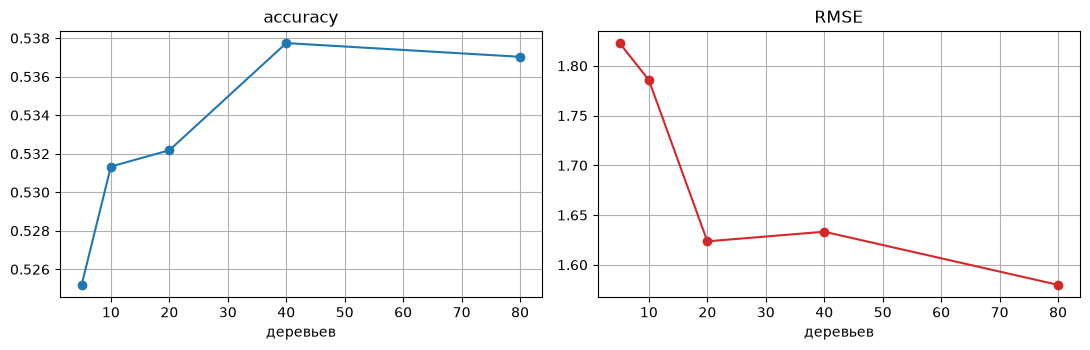

In [6]:
# --- число деревьев ---
accs, rmses = [], []
for n in (5, 10, 20, 40, 80):
    m = RandomForest(task="classification", n_trees=n, max_depth=10, min_samples_leaf=30,
                     sample_frac=0.5).fit(Xc_tr, yc_tr)
    accs.append(metrics.accuracy(yc_te, m.predict(Xc_te)))
    mr = RandomForest(task="regression", n_trees=n, max_depth=10, min_samples_leaf=10,
                      max_features="third", sample_frac=0.5).fit(Xr_tr, yr_tr)
    rmses.append(metrics.rmse(yr_te, mr.predict(Xr_te)))
    print(f"trees={n:3d}  accuracy={accs[-1]:.4f}  RMSE={rmses[-1]:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot((5, 10, 20, 40, 80), accs, "o-"); ax[0].set_title("accuracy"); ax[0].set_xlabel("деревьев")
ax[1].plot((5, 10, 20, 40, 80), rmses, "o-", color="tab:red"); ax[1].set_title("RMSE"); ax[1].set_xlabel("деревьев")
plt.tight_layout(); plt.show()

## 4. Гипотеза 2: размер случайного подпространства

`max_features` — главный регулятор корреляции деревьев: меньше признаков —
сильнее декорреляция, но слабее отдельные деревья.

In [7]:
# --- max_features: sqrt против трети и всех признаков ---
for mf in ("sqrt", "third", len(SHARE_FEATS)):
    m = RandomForest(task="classification", n_trees=40, max_depth=10, min_samples_leaf=30,
                     max_features=mf, sample_frac=0.5).fit(Xc_tr, yc_tr)
    mr = RandomForest(task="regression", n_trees=40, max_depth=10, min_samples_leaf=10,
                      max_features=mf, sample_frac=0.5).fit(Xr_tr, yr_tr)
    print(f"max_features={str(mf):5s}  accuracy={metrics.accuracy(yc_te, m.predict(Xc_te)):.4f}  "
          f"RMSE={metrics.rmse(yr_te, mr.predict(Xr_te)):.4f}")

max_features=sqrt   accuracy=0.5377  RMSE=2.1935


max_features=third  accuracy=0.5393  RMSE=1.6333


max_features=19     accuracy=0.5280  RMSE=0.9043


## 5. Гипотеза 3: доля подвыборки

Бэггинг на 0.5 вместо бутстрапа 1.0 добавляет разнообразия и ускоряет обучение.

In [8]:
# --- доля обучающей подвыборки на дерево ---
for frac in (0.3, 0.5, 0.7, 1.0):
    m = RandomForest(task="classification", n_trees=40, max_depth=10, min_samples_leaf=30,
                     sample_frac=frac).fit(Xc_tr, yc_tr)
    print(f"sample_frac={frac:.1f}  accuracy={metrics.accuracy(yc_te, m.predict(Xc_te)):.4f}  "
          f"AUC={metrics.roc_auc(yc_te, m.predict_proba(Xc_te)):.4f}")

sample_frac=0.3  accuracy=0.5333  AUC=0.5265


sample_frac=0.5  accuracy=0.5377  AUC=0.5276


sample_frac=0.7  accuracy=0.5411  AUC=0.5342


sample_frac=1.0  accuracy=0.5377  AUC=0.5312


## Выводы

1. Свой лес воспроизводит поведение sklearn: 40 деревьев дают accuracy 0.5377
   против 0.5389 у sklearn со 100 деревьями, AUC 0.528 против 0.532.
   В регрессии разрыв больше: RMSE 1.633 против 1.542 — 40 деревьев на подвыборке
   0.5 смещены сильнее, чем 100 деревьев на полной выборке.
2. Насыщение по числу деревьев — 20–40: accuracy 0.532 → 0.538, дальше плато;
   RMSE регрессии медленно падает до 80 деревьев (1.62 при 20 → 1.58 при 80).
3. `max_features` — сильный регулятор. В классификации `sqrt` и `third` равноценны
   (0.538 и 0.539), все 19 признаков хуже (0.528): деревья получаются слишком
   похожими, декорреляции нет. В регрессии картина обратная: все признаки дают
   RMSE 0.904 против 1.633 при `third` — сильные деревья на уровне доходности
   плюс усреднение выигрывают у слабых декоррелированных.
   Но 0.904 всё ещё хуже наивного прогноза «завтра = сегодня» (0.888 из ЛР-2):
   и лес не предсказывает уровень доходности, а воспроизводит инерцию.
4. Доля подвыборки 0.7 — лучший баланс (accuracy 0.541, AUC 0.534); 0.3 —
   слишком мало данных на дерево, 1.0 — слишком мало разнообразия.
5. Лес обгоняет одиночное дерево по AUC (0.532 у sklearn RF против 0.514
   у дерева глубины 6 из ЛР-3) — усреднение гасит дисперсию.
6. Accuracy ≈ 0.54: лес выжимает из признаков почти всё, что можно, но дневное
   направление цены остаётся почти случайным.
